In [6]:

import matplotlib.colors as colors
import matplotlib.pyplot as plt
import numpy as np 
from matplotlib.ticker import MaxNLocator as mnl

from tqdm import tqdm
import time 




In [11]:
'''19/10/2026'''

'''Magnetic moment constant'''

def phi(mu, mu_0): 
    return (mu - mu_0)/(mu + 2*mu_0)

'''Magnetic permeability in a vacuum'''
mu_0 = 4*np.pi *10**-7


'''Magnetic moment of Iron Grain'''
mu = 1.5*1e-3

'''Formula for gap distance between grains at equilibrium'''
def gap_distance(a, phi, L): 
    return ((3*a**3) * phi/2 * L**2)**(1/5)


'''Radii length scale'''

def phi(mu, mu_0): 
    return (mu - mu_0)/(mu + 2*mu_0)

mu_0 = 4*np.pi *10**-7

mu = 1.5*1e-3


phi = phi(mu, mu_0)



In [12]:
'''Ranges'''
#the values that are used for the equilibrium spacing 

a = np.linspace(1e-8,1e-6,1000)

R_j = 7*1e8


def L(r): 
    return r/3 


min_r = 0.64* R_j 
max_r = 1.13 * R_j



L_min = L(min_r)
L_max = L(max_r)
L = np.linspace(L_min, L_max, 1000)


print(L_min,L_max)


149333333.33333334 263666666.66666663


In [13]:
'''Gap distance for large scales'''
d = gap_distance(a,phi, L )





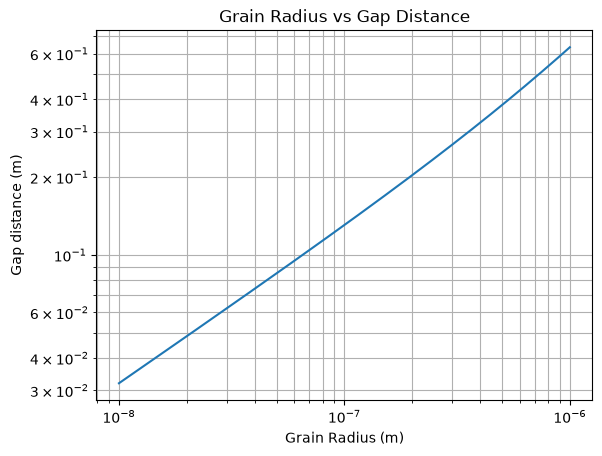

In [14]:
plt.loglog(a, d)
plt.xlabel('Grain Radius (m)')
#plt.hlines(y = (d_min, d_max), xmin = 0, xmax = 1e-6, colors = 'r', linestyle = ':')
plt.ylabel('Gap distance (m)')
plt.grid(True, which="both", ls="-")
plt.title('Grain Radius vs Gap Distance')
plt.show()

In [15]:
'''Ranges'''

g = np.linspace(1.78 * 1e1, 3 * 1e3, 1000)
T = np.linspace(500,3000,1000)
R = 8.314 
mu_iron = 2.36 * 1e-3


In [16]:
def scale_height(R,T,mu,g):
    return R*T/(mu*g)


H = scale_height(R,T,mu_iron, g)

print(len(g))

1000


(1000, 1000) (1000, 1000) (1000, 1000)
[155692.88389513 133332.14540271 116587.72203179 ...   5553.71925363
   5548.18745567   5542.66666667]
923.7777777777778
934157.3033707865


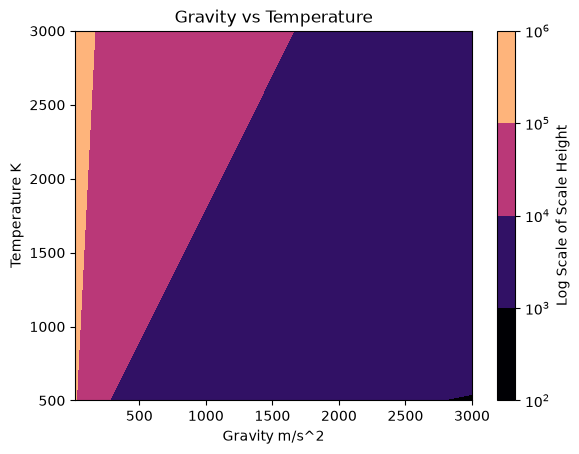

In [17]:
#Contour plot: 

#the values that are used for the equilibrium spacing 


#plotting a contour plot with the x axis being g and y axis being T 
#z is the scale height

[X,Y] = np.meshgrid(g,T)
fig,ax = plt.subplots(1,1)

Z = R*Y/(mu*X)



plt.title('Gravity vs Temperature')
print(X.shape, Y.shape, Z.shape)
plt.contourf(X,Y,Z, norm = colors.LogNorm(vmin = Z.min(), vmax =  Z.max()) ,cmap='magma')
plt.colorbar(label = 'Log Scale of Scale Height')

plt.xlabel('Gravity m/s^2')
plt.ylabel('Temperature K')


z = Z.flatten() #flattening z so that it can be used to calculate d as L is assumed to be proportional to H

print(z)

print(z.min())
print(z.max())

In [18]:
for i in tqdm(z): #for loop to calculate d 
    d2 = gap_distance(a,phi,i)

d2 = gap_distance(a, phi, Z)



100%|██████████| 1000000/1000000 [00:06<00:00, 143398.14it/s]


In [19]:
print(np.shape(d2))
d = gap_distance(a,phi,L) # d from global scale

(1000, 1000)


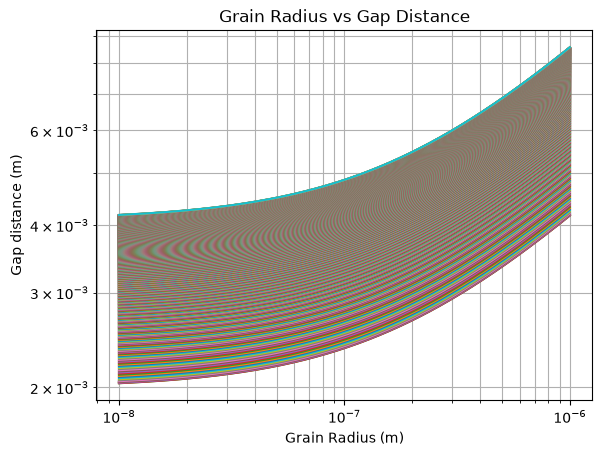

In [20]:
plt.loglog(a, d2)
plt.xlabel('Grain Radius (m)')
#plt.hlines(y = (d_min, d_max), xmin = 0, xmax = 1e-6, colors = 'r', linestyle = ':')
plt.ylabel('Gap distance (m)')
plt.grid(True, which="both", ls="-")
plt.title('Grain Radius vs Gap Distance')
plt.show()



In [21]:
plt.loglog(a, d2, color = 'r', label ='Scale Height Method')
plt.loglog(a,d, color = 'b', label = 'Star radii Method')
plt.xlabel('Grain Radius (m)')
#plt.hlines(y = (d_min, d_max), xmin = 0, xmax = 1e-6, colors = 'r', linestyle = ':')
plt.ylabel('Gap distance (m)')
plt.grid(True, which="both", ls="-", alpha= 0.5)
plt.yticks([1e-4,1e-3,1e-2,1e-1])
plt.title('Grain Radius vs Gap Distance')
plt.legend()
plt.show()

In [22]:
'''Starspot method'''

min_r = 0.64* R_j 
max_r = 1.13 * R_j



r_hemi = np.linspace(min_r, max_r, 100)

#note that the r_hemi and r_brown dwarf are the same 




eta = np.linspace(0.001, 0.22, 1000)




In [23]:
rad = []

for i in r_hemi: 
    for k in eta: 
        rad.append(i*np.sqrt(2*k))


L_starspot = np.array(rad)

print((L_starspot.min(), L_starspot.max()))

(np.float64(20035169.078398116), np.float64(524690041.83422416))


In [24]:

r_hemi = np.linspace(min_r, max_r, 1000)
r_hemi_min = r_hemi * np.sqrt(0.22*2) 
r_hemi_max = r_hemi * np.sqrt(0.001*2)

In [25]:

def L_starspot(eta, r): 
    return np.sqrt(2*eta) * r




L_starspot_original = L_starspot(eta, r_hemi)


d_starspot_original = gap_distance(a, phi, L_starspot_original)




In [26]:
'''L_spot = L_starspot(eta, max_r)'''


d_starspot_min = gap_distance(a, phi, r_hemi_min)
d_starspot_max = gap_distance(a, phi, r_hemi_max)


In [27]:
""" eta = np.linspace(0.001, 0.22, 10)


l = []
for i in r_hemi: 
    l.append(i* np.sqrt(2*eta))


l_array = np.array(l)

l_array_flatten = l_array.flatten()

d_starspot_average = gap_distance(a, phi, l_array_flatten) """


' eta = np.linspace(0.001, 0.22, 10)\n\n\nl = []\nfor i in r_hemi: \n    l.append(i* np.sqrt(2*eta))\n\n\nl_array = np.array(l)\n\nl_array_flatten = l_array.flatten()\n\nd_starspot_average = gap_distance(a, phi, l_array_flatten) '

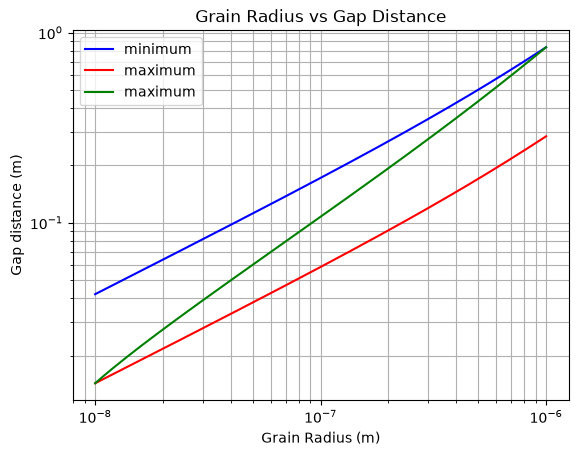

In [28]:
plt.loglog(a, d_starspot_min, color = 'blue', label = 'minimum')
plt.loglog(a,d_starspot_max, color = 'red', label = 'maximum')
plt.loglog(a,d_starspot_original, color = 'g', label = 'maximum')

plt.xlabel('Grain Radius (m)')
plt.legend()
#plt.hlines(y = (d_min, d_max), xmin = 0, xmax = 1e-6, colors = 'r', linestyle = ':')
plt.ylabel('Gap distance (m)')
plt.grid(True, which="both", ls="-")
plt.title('Grain Radius vs Gap Distance')
plt.show()

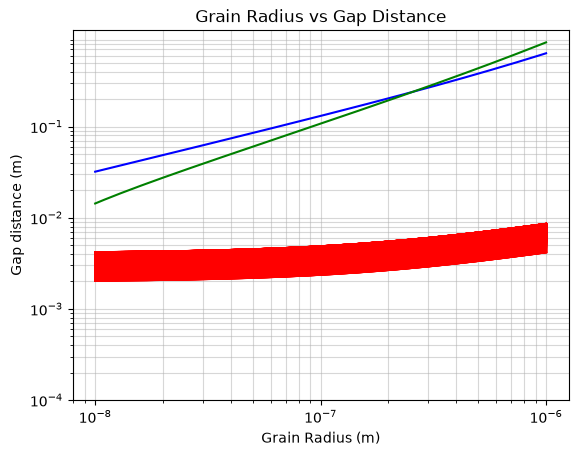

In [30]:
plt.loglog(a, d2, color = 'r', label ='Scale Height Method')
plt.loglog(a,d, color = 'b', label = 'Star radii Method')


plt.loglog(a,d_starspot_original,color = 'g', label = 'Starspot max')

plt.xlabel('Grain Radius (m)')
#plt.hlines(y = (d_min, d_max), xmin = 0, xmax = 1e-6, colors = 'r', linestyle = ':')
plt.ylabel('Gap distance (m)')
plt.grid(True, which="both", ls="-", alpha= 0.5)
plt.yticks([1e-4,1e-3,1e-2,1e-1])
plt.title('Grain Radius vs Gap Distance')
#plt.legend()
plt.show()

In [26]:
import import_ipynb 